# Spiffy Music Streaming
## User Retention, Paid Conversion, and Churn-Risk Optimization: End-to-End Analysis

### Project Flow

This notebook brings the full analysis together in one end-to-end, business-ready workflow:

> Data assets & definitions → Data quality → Business baseline → User segmentation → Content & ad experience diagnosis → Conversion funnel → Churn prediction → Model validation → Risk queues → Strategy design → A/B test → Production monitoring

### Core Business Questions

1. **Which user segments and acquisition channels contribute the most churn?**
2. **Which behavioral signals identify high-risk users before they churn?**
3. **Which problems should be solved with operational strategy, and which need product experiments?**
4. **How can a one-off analysis become a daily risk-identification and intervention system?**

### Skills Demonstrated

- Building a user-level analysis and modeling table from raw event tables
- Separating churn rate from churn contribution, rather than chasing small, extreme segments
- Identifying interactions among acquisition quality, content engagement, ad friction, and lifecycle stage
- Predicting churn with Logistic Regression and Random Forest
- Validating models with ROC-AUC, PR-AUC, thresholds, risk deciles, and Top-K lift
- Turning a risk model into capacity-constrained, testable, and monitorable business queues
- Making clear that **predictive correlation is not causal impact**: strategy effects must be validated with A/B tests

## Executive Summary

Based on the Spiffy data, the analysis reached six verifiable conclusions:

1. **The overall 14-day churn rate is 47.56%.** The problem is not one small segment; churn is concentrated at scale.
2. `casual_free` users are 35.82% of users but contribute **48.91% of all churners**. `inactive` users have the highest churn rate but are a smaller group.
3. `paid_social` shows high churn, low paid conversion, and low revenue quality at the same time: **60.24%** churn and **12.59%** paid conversion, vs. only **36.10%** churn and **22.80%** paid conversion for `referral`.
4. Content behavior separates risk better than demographics. `low_intent_new` churns at **82.16%**, while `playlist_builder` churns at only **18.21%**.
5. Home recommendations drive the most listening events but perform poorly: `home_recommendation` has a **25.81%** skip rate, far above **8.31%** for `user_playlist`.
6. Logistic Regression reaches about **0.79** ROC-AUC on the untouched test set. The top 20% of test-set risk users have an actual churn rate of about **79.7%**, a **1.67x lift** over the baseline.

**The recommendation is not "send coupons to every high-risk user." It is separate queues:**

- New / low-intent users: content activation
- High-value Premium users at risk: payment and renewal recovery
- Paid Social users: joint channel and onboarding optimization
- Low-activity users under high ad pressure: small-scale ad-frequency experiment
- Users with search intent but no saved content: Search-to-Playlist product experiment

# 0. Environment & Data Loading

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 180)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

RANDOM_STATE = 42

# In Colab: upload the 5 CSVs to /content/data.
# Locally: the notebook checks the project data folders, including ../data in this repo.
def find_data_dir():
    candidates = [
        '/content/data',
        '../data',
        '/mnt/data/spotify_user_behavior_data_only',
        './data',
        os.getcwd(),
    ]
    required = {
        'users.csv',
        'listening_events.csv',
        'subscription_events.csv',
        'ad_events.csv',
        'feature_table.csv',
    }
    for candidate in candidates:
        if os.path.isdir(candidate) and required.issubset(set(os.listdir(candidate))):
            return candidate
    raise FileNotFoundError(
        'Data not found. Put users.csv, listening_events.csv, subscription_events.csv, '
        'ad_events.csv, and feature_table.csv in ../data (or /content/data in Colab).'
    )

DATA_DIR = find_data_dir()
print('Data directory:', DATA_DIR)

Data directory: ../data


In [2]:
users = pd.read_csv(os.path.join(DATA_DIR, 'users.csv'))
listening_events = pd.read_csv(os.path.join(DATA_DIR, 'listening_events.csv'))
subscription_events = pd.read_csv(os.path.join(DATA_DIR, 'subscription_events.csv'))
ad_events = pd.read_csv(os.path.join(DATA_DIR, 'ad_events.csv'))
feature_table = pd.read_csv(os.path.join(DATA_DIR, 'feature_table.csv'))

# Parse all date and time columns.
users['signup_date'] = pd.to_datetime(users['signup_date'])
listening_events['event_timestamp'] = pd.to_datetime(listening_events['event_timestamp'])
subscription_events['event_timestamp'] = pd.to_datetime(subscription_events['event_timestamp'])
ad_events['event_timestamp'] = pd.to_datetime(ad_events['event_timestamp'])
feature_table['snapshot_date'] = pd.to_datetime(feature_table['snapshot_date'])
feature_table['signup_date'] = pd.to_datetime(feature_table['signup_date'])

# Helper fields for the analysis.
feature_table['retained_14d'] = 1 - feature_table['churn_label_14d']
feature_table['signup_month'] = feature_table['signup_date'].dt.to_period('M').astype(str)
feature_table['content_actions_30d'] = (
    feature_table['liked_songs_30d'] + feature_table['playlist_adds_30d']
)
feature_table['tenure_bucket'] = pd.cut(
    feature_table['tenure_days'],
    bins=[-1, 30, 90, 180, np.inf],
    labels=['0-30d', '31-90d', '91-180d', '180d+'],
)

print('Loaded tables:', {
    'users': users.shape,
    'listening_events': listening_events.shape,
    'subscription_events': subscription_events.shape,
    'ad_events': ad_events.shape,
    'feature_table': feature_table.shape,
})

Loaded tables: {'users': (50000, 11), 'listening_events': (1072063, 15), 'subscription_events': (104498, 10), 'ad_events': (310438, 10), 'feature_table': (50000, 57)}


# 1. Data Overview: Data Assets, Grain, and Time Coverage

,table,grain,rows,columns,date_min,date_max
0,users,one row per user,50000,11,2025-01-01 00:00:00,2026-03-14 00:00:00
1,listening_events,one row per listening event,1072063,15,2026-01-01 00:00:06,2026-04-14 23:59:57
2,subscription_events,one row per subscription event,104498,10,2025-01-04 07:04:24,2026-04-16 19:22:30
3,ad_events,one row per ad impression/event,310438,10,2026-01-01 00:00:03,2026-04-14 23:59:45
4,feature_table,one row per user at snapshot,50000,57,2026-04-01 00:00:00,2026-04-01 00:00:00


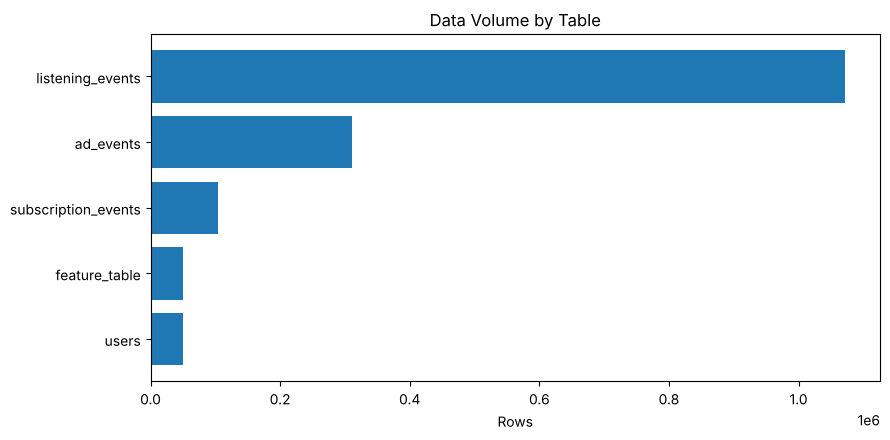

In [3]:
# Business grain and time coverage of each table.
table_specs = {
    'users': ('one row per user', users, 'signup_date'),
    'listening_events': ('one row per listening event', listening_events, 'event_timestamp'),
    'subscription_events': ('one row per subscription event', subscription_events, 'event_timestamp'),
    'ad_events': ('one row per ad impression/event', ad_events, 'event_timestamp'),
    'feature_table': ('one row per user at snapshot', feature_table, 'snapshot_date'),
}

rows = []
for name, (grain, df, date_col) in table_specs.items():
    rows.append({
        'table': name,
        'grain': grain,
        'rows': len(df),
        'columns': df.shape[1],
        'date_min': df[date_col].min(),
        'date_max': df[date_col].max(),
    })

table_overview = pd.DataFrame(rows)
display(table_overview)

plt.figure(figsize=(9, 4.5))
ordered = table_overview.sort_values('rows')
plt.barh(ordered['table'], ordered['rows'])
plt.title('Data Volume by Table')
plt.xlabel('Rows')
plt.tight_layout()
plt.show()

### Reading the Tables

- `listening_events` is the largest behavioral table (about 1.07 million events), used to analyze recommendation sources, skips, completions, likes, and search behavior.
- `ad_events` records ad impressions, clicks, completions, and revenue, used to evaluate ad monetization and experience.
- `subscription_events` records subscription events such as trial, paid, renewal, and cancel.
- `feature_table` is the **user-level table**: one row per user, with behavioral features from the observation window and the 14-day-forward churn label. It is rebuilt from the raw events and validated in `sql/01_user_metrics.sql`.

### Takeaway

> I used raw event tables for behavioral diagnosis and a one-row-per-user feature table for segmentation and churn modeling. The snapshot-based design separates historical features from future labels and avoids event-level duplication in user metrics.

## 1.1 Data Quality Checks: Is the Table Ready for Analysis and Modeling?

In [4]:
qa = pd.DataFrame({
    'check': [
        'row_count',
        'unique_user_count',
        'duplicated_user_id',
        'missing_cells',
        'snapshot_count',
        'target_positive_rate',
    ],
    'value': [
        len(feature_table),
        feature_table['user_id'].nunique(),
        feature_table['user_id'].duplicated().sum(),
        feature_table.isna().sum().sum(),
        feature_table['snapshot_date'].nunique(),
        feature_table['churn_label_14d'].mean(),
    ],
})
display(qa)

# Basic sanity checks on metric definitions.
assert feature_table['user_id'].duplicated().sum() == 0, 'feature_table is not one row per user.'
assert feature_table['churn_label_14d'].isin([0, 1]).all(), 'churn label is not binary.'
assert (feature_table['active_days_30d'] >= feature_table['active_days_7d']).all()
assert (feature_table['listen_minutes_30d'] >= feature_table['listen_minutes_7d']).all()
print('Core QA checks passed.')

,check,value
0,row_count,"50,000.0000"
1,unique_user_count,"50,000.0000"
2,duplicated_user_id,0.0000
3,missing_cells,0.0000
4,snapshot_count,1.0000
5,target_positive_rate,0.4756


Core QA checks passed.


### Key Limitation

The table has only one `snapshot_date`. Therefore:

- Model validation here is a holdout across users;
- It cannot replace a true out-of-time backtest;
- Production would need weekly or monthly snapshots, training on past months and validating on later ones, to test for drift over time.

**A single random split should not be presented as full production validation.**

# 2. Business Baseline: Overall Retention, Conversion, Engagement, and Revenue

,metric,value
0,14d churn rate,0.4756
1,14d retention rate,0.5244
2,30d paid conversion rate,0.1739
3,30d trial exposure rate,0.2577
4,30d trial start rate,0.1238
5,avg active days 30d,6.4347
6,avg listening minutes 30d,38.5309
7,avg total revenue 30d,3.8902


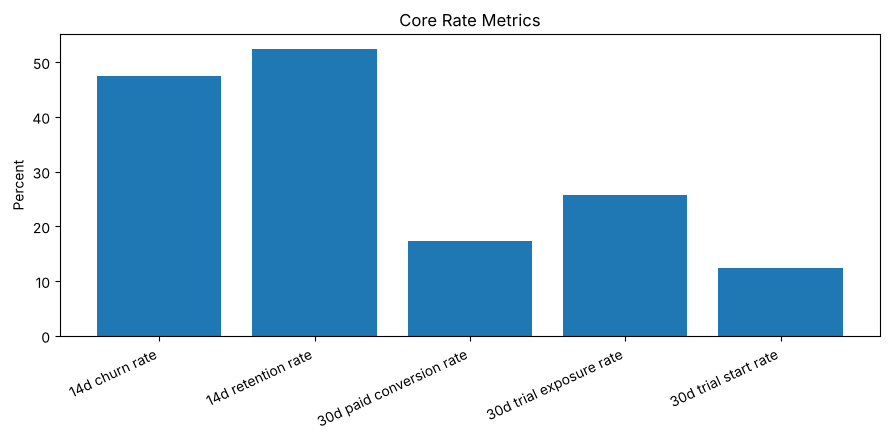

In [5]:
baseline = pd.DataFrame({
    'metric': [
        '14d churn rate',
        '14d retention rate',
        '30d paid conversion rate',
        '30d trial exposure rate',
        '30d trial start rate',
        'avg active days 30d',
        'avg listening minutes 30d',
        'avg total revenue 30d',
    ],
    'value': [
        feature_table['churn_label_14d'].mean(),
        feature_table['retained_14d'].mean(),
        feature_table['paid_conversion_30d'].mean(),
        feature_table['trial_exposed_30d'].mean(),
        feature_table['trial_started_30d'].mean(),
        feature_table['active_days_30d'].mean(),
        feature_table['listen_minutes_30d'].mean(),
        feature_table['total_revenue_30d'].mean(),
    ],
})
display(baseline)

rate_metrics = baseline.iloc[:5].copy()
plt.figure(figsize=(9, 4.5))
plt.bar(rate_metrics['metric'], rate_metrics['value'] * 100)
plt.title('Core Rate Metrics')
plt.ylabel('Percent')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

In [6]:
print(f"Users: {len(feature_table):,}")
print(f"14d churn rate: {feature_table['churn_label_14d'].mean():.2%}")
print(f"14d retention rate: {feature_table['retained_14d'].mean():.2%}")
print(f"30d paid conversion rate: {feature_table['paid_conversion_30d'].mean():.2%}")
print(f"Average active days in 30d: {feature_table['active_days_30d'].mean():.2f}")
print(f"Average listening minutes in 30d: {feature_table['listen_minutes_30d'].mean():.2f}")
print(f"Average total revenue in 30d: ${feature_table['total_revenue_30d'].mean():.2f}")

Users: 50,000
14d churn rate: 47.56%
14d retention rate: 52.44%
30d paid conversion rate: 17.39%
Average active days in 30d: 6.43
Average listening minutes in 30d: 38.53
Average total revenue in 30d: $3.89


### Baseline Insight

- The 14-day churn rate is close to half, so the work should not start with niche segment optimization; it should first identify the risk sources with the **largest scale and highest contribution**.
- Paid conversion and retention cannot be read in isolation. Some recent users convert to paid at higher rates but still retain poorly, which may reflect trial and lifecycle differences.
- The rest of the analysis therefore tracks **Rate, Volume, Contribution, Revenue, and Actionability** together.

# 3. Segmentation Analysis: The Real Problems by Segment

In [7]:
def segment_summary(df, segment_col):
    result = (
        df.groupby(segment_col, dropna=False)
          .agg(
              users=('user_id', 'size'),
              churners=('churn_label_14d', 'sum'),
              churn_rate=('churn_label_14d', 'mean'),
              paid_conversion=('paid_conversion_30d', 'mean'),
              avg_active_days=('active_days_30d', 'mean'),
              avg_listen_minutes=('listen_minutes_30d', 'mean'),
              avg_content_actions=('content_actions_30d', 'mean'),
              avg_ad_load=('ad_impressions_per_active_day', 'mean'),
              avg_total_revenue=('total_revenue_30d', 'mean'),
          )
          .reset_index()
    )
    result['user_share'] = result['users'] / len(df)
    result['churn_contribution'] = result['churners'] / df['churn_label_14d'].sum()
    return result.sort_values('churn_contribution', ascending=False)

## 3.1 Lifecycle Stage: A High Rate Does Not Mean Top Priority

,lifecycle_stage,users,churners,churn_rate,paid_conversion,avg_active_days,avg_listen_minutes,avg_content_actions,avg_ad_load,avg_total_revenue,user_share,churn_contribution
0,casual_free,17912,11631,0.6493,0.0010,3.2779,16.2397,0.3647,0.9132,0.0519,0.3582,0.4891
2,inactive,4502,3638,0.8081,0.0018,0.0000,0.0000,0.0000,0.0000,0.0261,0.0900,0.1530
3,premium_at_risk,5439,3128,0.5751,0.4617,1.5247,7.2561,0.1680,0.0438,10.1690,0.1088,0.1315
4,premium_engaged,13306,2862,0.2151,0.4626,11.2945,71.2676,2.3860,0.0648,10.2795,0.2661,0.1204
1,engaged_free,7592,1939,0.2554,0.0005,12.7214,79.1600,2.4278,0.8093,0.1676,0.1518,0.0815
5,trial_user,1249,581,0.4652,0.0000,6.2954,37.5703,1.1217,0.7594,0.0803,0.0250,0.0244


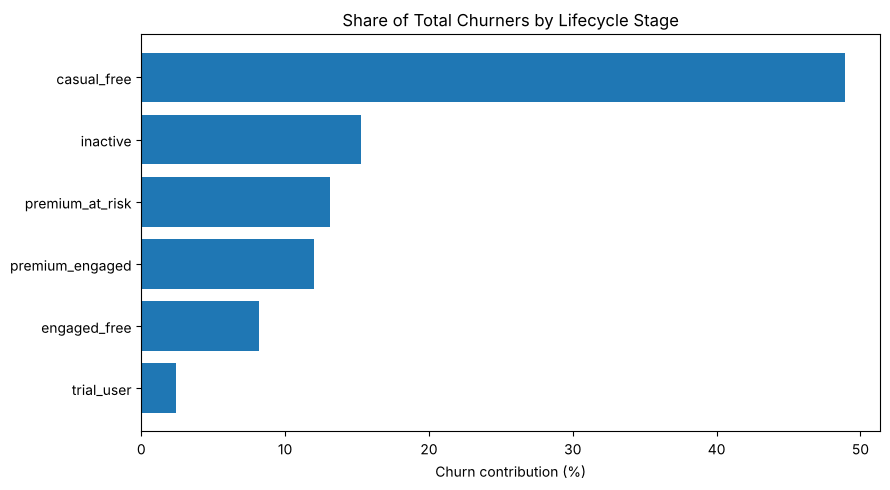

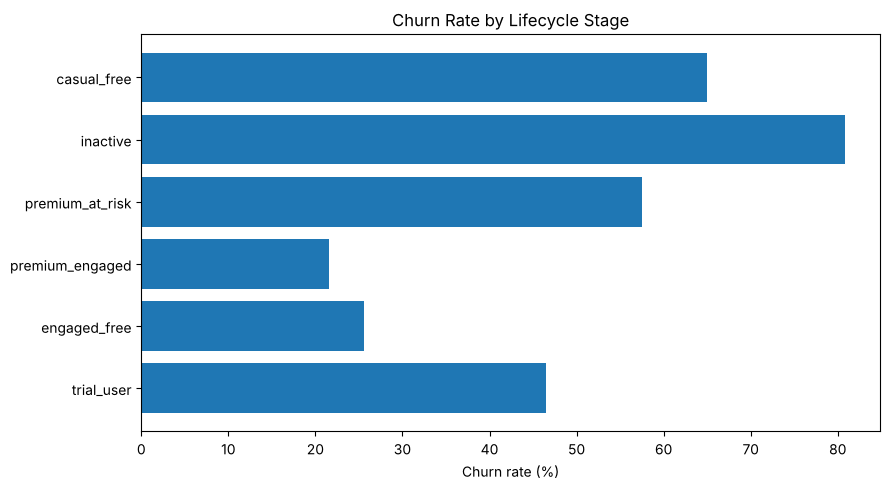

In [8]:
lifecycle = segment_summary(feature_table, 'lifecycle_stage')
display(lifecycle)

ordered = lifecycle.sort_values('churn_contribution')
plt.figure(figsize=(9, 5))
plt.barh(ordered['lifecycle_stage'], ordered['churn_contribution'] * 100)
plt.title('Share of Total Churners by Lifecycle Stage')
plt.xlabel('Churn contribution (%)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.barh(ordered['lifecycle_stage'], ordered['churn_rate'] * 100)
plt.title('Churn Rate by Lifecycle Stage')
plt.xlabel('Churn rate (%)')
plt.tight_layout()
plt.show()

### Facts

- `casual_free` has 17,912 users with a **64.93%** churn rate, contributing **48.91%** of all churners.
- `inactive` has the highest churn rate, **80.81%**, but contributes only about **15.30%** of churners.
- `premium_at_risk` has 5,439 users, a **57.51%** churn rate, and average 30-day revenue of about **$10.17**.

### Insight

There are two distinct kinds of opportunity:

1. **A volume retention problem**: `casual_free`, the largest contributor, suited to product-led activation;
2. **A value retention problem**: `premium_at_risk`, smaller but high-revenue, suited to payment and renewal recovery.

### Recommendation

A single "high-risk coupon" strategy will not work. Split it into two operational queues:

- Free-user queue: improve content activation;
- Premium-user queue: prioritize payment failures, renewals, and benefit communication.

## 3.2 Acquisition Channel: Acquisition Volume Is Not Acquisition Quality

,acquisition_channel,users,churners,churn_rate,paid_conversion,avg_active_days,avg_listen_minutes,avg_content_actions,avg_ad_load,avg_total_revenue,user_share,churn_contribution
0,app_store,12534,5859,0.4674,0.1758,6.5136,38.7651,1.2050,0.4864,3.8549,0.2507,0.2464
3,organic_search,11944,5491,0.4597,0.1703,6.5689,39.2673,1.1953,0.4937,3.8526,0.2389,0.2309
4,paid_social,8993,5417,0.6024,0.1259,5.1881,28.8337,0.8215,0.5490,2.9474,0.1799,0.2278
5,referral,6495,2345,0.3610,0.2280,7.4414,47.2298,1.5032,0.4203,5.1172,0.1299,0.0986
6,student_partner,3975,1874,0.4714,0.1869,6.7052,41.3593,1.2941,0.4794,4.0252,0.0795,0.0788
2,influencer,4036,1845,0.4571,0.1863,6.6296,40.2599,1.2359,0.4955,4.0899,0.0807,0.0776
1,email_campaign,2023,948,0.4686,0.1735,6.5428,38.9053,1.1681,0.4872,3.9182,0.0405,0.0399


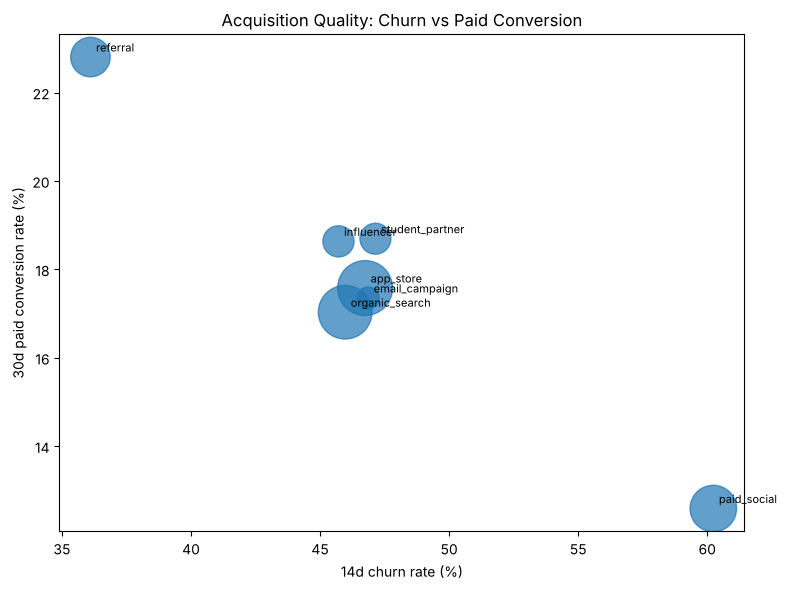

In [9]:
channel = segment_summary(feature_table, 'acquisition_channel')
display(channel)

plt.figure(figsize=(8, 6))
plt.scatter(
    channel['churn_rate'] * 100,
    channel['paid_conversion'] * 100,
    s=channel['users'] / 8,
    alpha=0.7,
)
for _, row in channel.iterrows():
    plt.annotate(
        row['acquisition_channel'],
        (row['churn_rate'] * 100, row['paid_conversion'] * 100),
        xytext=(4, 4),
        textcoords='offset points',
        fontsize=8,
    )
plt.title('Acquisition Quality: Churn vs Paid Conversion')
plt.xlabel('14d churn rate (%)')
plt.ylabel('30d paid conversion rate (%)')
plt.tight_layout()
plt.show()

### Facts

- `paid_social` has 8,993 users with **60.24%** churn, **12.59%** paid conversion, and average revenue of about **$2.95**.
- The channel is only 17.99% of users but contributes **22.78%** of churners.
- `referral` has **36.10%** churn, **22.80%** paid conversion, and average revenue of about **$5.12**.

### Insight

The problem is not simply "Paid Social traffic is bad." Acquisition optimization is likely tuned for sign-ups or trial starts rather than for **retained paid users**.

### Recommendation

Upgrade the channel evaluation metric to:

> 30-day retained paid conversion × expected revenue, rather than signup volume or cheap CPA.

In practice:

- Break `paid_social` down further by creative, device, and landing experience;
- Build high-quality lookalike audiences from `referral` users' behavior and personas;
- In channel budget experiments, make retained paid conversion the primary metric and acquisition volume the guardrail.

## 3.3 Channel × Device: Quality Differences Within the Same Channel

In [10]:
channel_device = (
    feature_table.groupby(['acquisition_channel', 'primary_device'])
    .agg(
        users=('user_id', 'size'),
        churn_rate=('churn_label_14d', 'mean'),
        paid_conversion=('paid_conversion_30d', 'mean'),
        avg_revenue=('total_revenue_30d', 'mean'),
        avg_active_days=('active_days_30d', 'mean'),
    )
    .reset_index()
)
channel_device = channel_device[channel_device['users'] >= 300]

display(channel_device.sort_values('paid_conversion', ascending=False).head(12))
display(channel_device.sort_values('churn_rate', ascending=False).head(12))

,acquisition_channel,primary_device,users,churn_rate,paid_conversion,avg_revenue,avg_active_days
27,referral,mobile_ios,2599,0.3451,0.2474,5.5235,7.6506
26,referral,mobile_android,2255,0.3703,0.2213,5.0755,7.4129
29,referral,web,593,0.3693,0.2040,4.4639,7.3069
7,email_campaign,mobile_ios,804,0.4614,0.1990,4.3833,6.5448
12,influencer,mobile_ios,1582,0.4671,0.1979,4.3539,6.6574
32,student_partner,mobile_ios,1576,0.4689,0.1967,4.2525,6.5768
2,app_store,mobile_ios,4981,0.4684,0.1961,4.2713,6.4877
25,referral,desktop,839,0.3790,0.1931,4.4893,6.9178
11,influencer,mobile_android,1459,0.4503,0.1905,4.0046,6.4236
10,influencer,desktop,515,0.4350,0.1903,4.1747,6.7398


,acquisition_channel,primary_device,users,churn_rate,paid_conversion,avg_revenue,avg_active_days
21,paid_social,mobile_android,3150,0.6102,0.1219,2.8874,5.2616
20,paid_social,desktop,1193,0.6085,0.1039,2.6409,5.0813
24,paid_social,web,800,0.5975,0.1200,2.4349,5.0175
22,paid_social,mobile_ios,3553,0.5964,0.1385,3.2602,5.2069
34,student_partner,web,364,0.5055,0.1676,3.6450,6.5165
30,student_partner,desktop,515,0.4835,0.1864,3.9600,6.8039
4,app_store,web,1135,0.4793,0.1304,2.9993,6.1295
6,email_campaign,mobile_android,702,0.4758,0.1752,3.7416,6.5313
19,organic_search,web,1122,0.4750,0.1471,3.3899,6.6417
14,influencer,web,371,0.4744,0.1159,3.2184,6.9919


### Specific Opportunities

- `referral × mobile_ios` has paid conversion of about **24.74%** and churn of about **34.51%**.
- `paid_social × mobile_android` has churn of about **61.02%**.

So channel strategy cannot be set from channel totals alone. A more targeted action:

> Treat Paid Social Android as its own diagnostic unit and check whether ad creative promises, landing pages, permission flows, and day-one recommendations are consistent, instead of cutting the entire Paid Social budget.

## 3.4 Content Engagement: Saved Content Separates Risk Better Than Demographics

,music_persona,users,churners,churn_rate,paid_conversion,avg_active_days,avg_listen_minutes,avg_content_actions,avg_ad_load,avg_total_revenue,user_share,churn_contribution
0,casual_listener,13528,8337,0.6163,0.1258,3.1400,11.9960,0.3317,0.5552,2.9290,0.2706,0.3506
3,low_intent_new,5096,4187,0.8216,0.0612,0.9343,2.7616,0.0502,0.4380,1.4973,0.1019,0.1761
1,commute_listener,8870,3591,0.4048,0.2041,7.5520,50.5291,1.1404,0.4637,4.5175,0.1774,0.1510
2,discovery_seeker,7899,2777,0.3516,0.2185,9.0341,43.5684,1.4582,0.4603,4.8472,0.1580,0.1168
5,podcast_heavy,4515,1999,0.4427,0.1829,6.6292,83.7133,0.8749,0.5668,3.9958,0.0903,0.0841
6,social_listener,3481,1684,0.4838,0.1637,5.7274,24.3960,0.7458,0.5041,3.6257,0.0696,0.0708
4,playlist_builder,6611,1204,0.1821,0.2647,13.0514,74.8695,3.9487,0.4153,5.7833,0.1322,0.0506


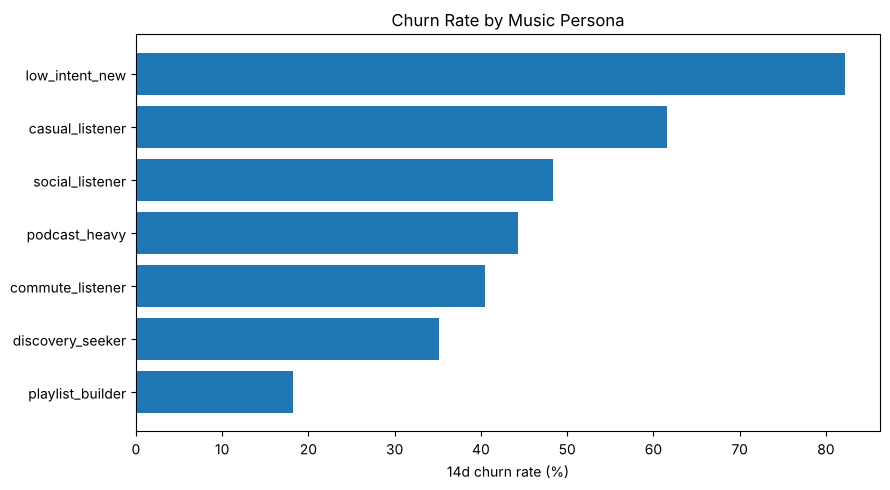

In [11]:
persona = segment_summary(feature_table, 'music_persona')
display(persona)

ordered = persona.sort_values('churn_rate')
plt.figure(figsize=(9, 5))
plt.barh(ordered['music_persona'], ordered['churn_rate'] * 100)
plt.title('Churn Rate by Music Persona')
plt.xlabel('14d churn rate (%)')
plt.tight_layout()
plt.show()

### Facts

- `low_intent_new` churns at **82.16%**, with only about 2.76 minutes of listening in 30 days on average.
- `playlist_builder` churns at only **18.21%**, with about 3.95 content actions on average.
- Churn differences across age groups are far smaller than differences across personas and activity levels.

### Insight

The actionable risk signal is not "young users churn more." It is:

> The user has not formed a repeatable content path: no searches, likes, playlists, or regular sessions.

Strategy should therefore start from **habit formation and content ownership**, not demographics.

## 3.5 Recommendation Source: Home Recommendations Have Volume but Weak Quality

,recommendation_source,events,users,completion_rate,skip_rate,like_rate,playlist_add_rate,avg_play_ratio,event_share
2,home_recommendation,324121,43288,0.3269,0.2581,0.0657,0.0495,0.6005,0.3023
6,user_playlist,265209,39369,0.4047,0.0831,0.1161,0.0671,0.7179,0.2474
1,editorial_playlist,141625,36219,0.3615,0.1787,0.0698,0.0522,0.6533,0.1321
5,search,140654,35666,0.3627,0.1774,0.0892,0.0715,0.6541,0.1312
4,radio,83170,29461,0.3618,0.1762,0.0684,0.0456,0.6550,0.0776
0,artist_page,64442,27541,0.3622,0.1788,0.0673,0.0509,0.6537,0.0601
3,podcast_tab,52842,20308,0.3580,0.1863,0.0635,0.0363,0.6451,0.0493


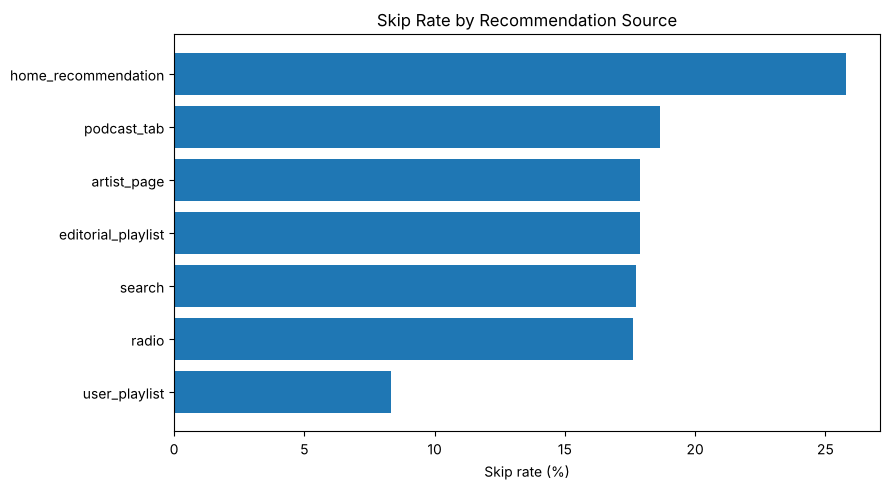

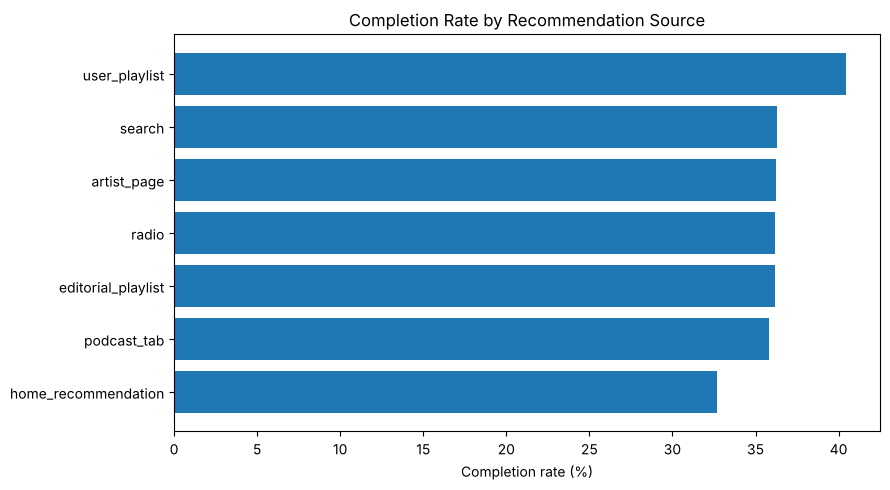

In [12]:
listening_events['play_ratio'] = (
    listening_events['play_duration_sec'] /
    listening_events['track_duration_sec'].replace(0, np.nan)
)

recommendation_source = (
    listening_events.groupby('recommendation_source')
    .agg(
        events=('event_id', 'size'),
        users=('user_id', 'nunique'),
        completion_rate=('completed_flag', 'mean'),
        skip_rate=('skipped_flag', 'mean'),
        like_rate=('liked_flag', 'mean'),
        playlist_add_rate=('playlist_add_flag', 'mean'),
        avg_play_ratio=('play_ratio', 'mean'),
    )
    .reset_index()
)
recommendation_source['event_share'] = recommendation_source['events'] / len(listening_events)
display(recommendation_source.sort_values('events', ascending=False))

plot_data = recommendation_source.sort_values('skip_rate')
plt.figure(figsize=(9, 5))
plt.barh(plot_data['recommendation_source'], plot_data['skip_rate'] * 100)
plt.title('Skip Rate by Recommendation Source')
plt.xlabel('Skip rate (%)')
plt.tight_layout()
plt.show()

plot_data = recommendation_source.sort_values('completion_rate')
plt.figure(figsize=(9, 5))
plt.barh(plot_data['recommendation_source'], plot_data['completion_rate'] * 100)
plt.title('Completion Rate by Recommendation Source')
plt.xlabel('Completion rate (%)')
plt.tight_layout()
plt.show()

### Facts

- `home_recommendation` accounts for about **30.23%** of all listening events, but has a **25.81%** skip rate and **32.69%** completion rate.
- `user_playlist` has only an **8.31%** skip rate, **40.47%** completion rate, and **11.61%** like rate.
- `search` has a like rate of about **8.92%** and playlist-add rate of about **7.15%**, showing that active search is high-intent behavior.

### Insight

Home recommendations do not lack traffic; they have **high exposure and low efficiency**. The home page may be carrying too much exploratory traffic without quickly helping new users build reusable content assets.

### Non-obvious Recommendation

Rather than simply adding more recommendation cards, test:

1. Auto-generating a saveable temporary playlist after a new user searches;
2. Prioritizing one-tap-saveable themed playlists on the home page over single-track streams;
3. Using popular or situational playlists for users without established preferences, and personalizing once enough signal exists.

Primary metric: D14 retention. Secondary metrics: playlist adds and active days. Guardrail: skip rate.

## 3.6 Ad Load: Don't Mistake Correlation for Ads Causing Churn

,active_level_30d,ad_load_bucket,users,churn_rate,avg_listen_minutes,avg_skip_rate,avg_ad_revenue,avg_ad_load
0,high,low,4175,0.1669,97.2050,0.1734,0.1813,0.7659
1,high,medium,327,0.1315,118.3606,0.1695,0.4844,1.8869
3,inactive,no_ads,4502,0.8081,0.0000,0.0000,0.0088,0.0000
7,low,no_ads,2762,0.7339,6.4127,0.2310,0.0000,0.0000
5,low,low,5499,0.6994,9.4092,0.2362,0.0262,0.8538
6,low,medium,2099,0.7170,7.4942,0.2433,0.0576,2.4133
4,low,high,142,0.7535,4.9926,0.1919,0.0893,5.6690
10,medium,no_ads,378,0.6032,22.5150,0.2005,0.0000,0.0000
8,medium,low,9361,0.5030,34.7693,0.1970,0.0685,0.7124
9,medium,medium,753,0.5405,35.8807,0.1907,0.1698,1.9290


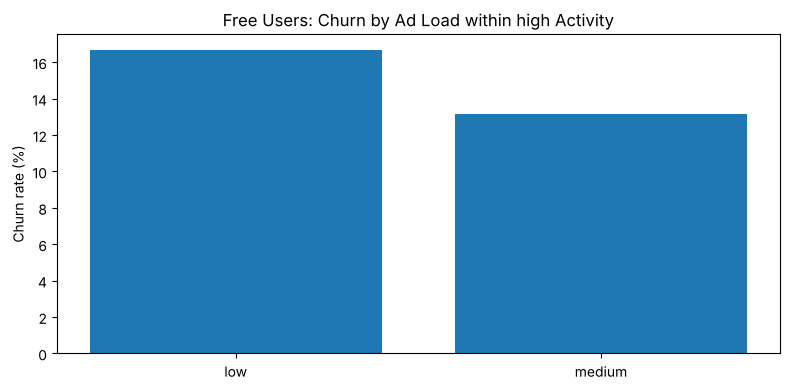

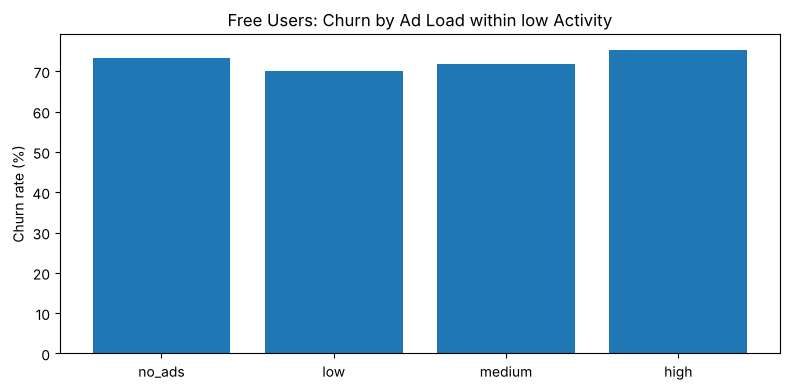

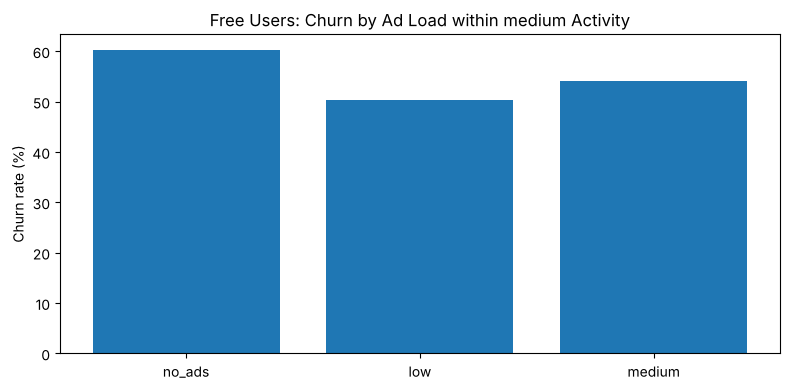

In [13]:
free_users = feature_table[feature_table['subscription_type'] == 'free'].copy()

ad_activity = (
    free_users.groupby(['active_level_30d', 'ad_load_bucket'])
    .agg(
        users=('user_id', 'size'),
        churn_rate=('churn_label_14d', 'mean'),
        avg_listen_minutes=('listen_minutes_30d', 'mean'),
        avg_skip_rate=('skip_rate_30d', 'mean'),
        avg_ad_revenue=('ad_revenue_30d', 'mean'),
        avg_ad_load=('ad_impressions_per_active_day', 'mean'),
    )
    .reset_index()
)
ad_activity = ad_activity[ad_activity['users'] >= 50]
display(ad_activity.sort_values(['active_level_30d', 'avg_ad_load']))

# Compare within activity levels so inactive/no_ads users do not distort the overall relationship.
plot_data = ad_activity[ad_activity['active_level_30d'].isin(['low', 'medium', 'high'])].copy()
for level, group in plot_data.groupby('active_level_30d'):
    group = group.sort_values('avg_ad_load')
    plt.figure(figsize=(8, 4))
    plt.bar(group['ad_load_bucket'], group['churn_rate'] * 100)
    plt.title(f'Free Users: Churn by Ad Load within {level} Activity')
    plt.ylabel('Churn rate (%)')
    plt.tight_layout()
    plt.show()

### Key Findings

In the raw summary, users with high ad load churn heavily, but the relationship is badly confounded by activity level:

- Many `no_ads` users are completely inactive, so they see no ads yet still churn at high rates;
- Among `low`-activity users, churn for low / medium / high ad load is about 69.94% / 71.70% / 75.35%;
- Only about 142 users fall in the `high` ad-load cell of that segment, too few to justify reducing ads across the board;
- Among highly active users, medium ad load does not churn more than low ad load.

### Insight

**Low activity is the stronger root cause; ad pressure looks more like an amplifier that needs to be tested in specific segments.**

### Recommendation

Do not reduce ads site-wide. Limit experiment eligibility to:

> Free users + low/medium activity + medium/high ad load + high model risk.

The treatment can reduce ad frequency or delay the first ad. Primary metric: D14 retention. Guardrails: ad revenue per eligible user and listening minutes.

## 3.7 Tenure / Cohort: Recent Users Are Riskier, but Not Necessarily Due to Acquisition Quality

,tenure_bucket,users,churners,churn_rate,paid_conversion,avg_active_days,avg_listen_minutes,avg_content_actions,avg_ad_load,avg_total_revenue,user_share,churn_contribution
3,180d+,27893,13162,0.4719,0.1540,6.5372,39.0394,1.1968,0.4983,3.4226,0.5579,0.5535
2,91-180d,12348,5805,0.4701,0.1699,6.6295,39.9631,1.2373,0.4811,4.4874,0.2470,0.2441
1,31-90d,8248,3963,0.4805,0.2079,6.1900,37.1972,1.1182,0.4896,4.4537,0.1650,0.1667
0,0-30d,1511,849,0.5619,0.3891,4.2879,24.7202,0.7578,0.4443,4.5661,0.0302,0.0357


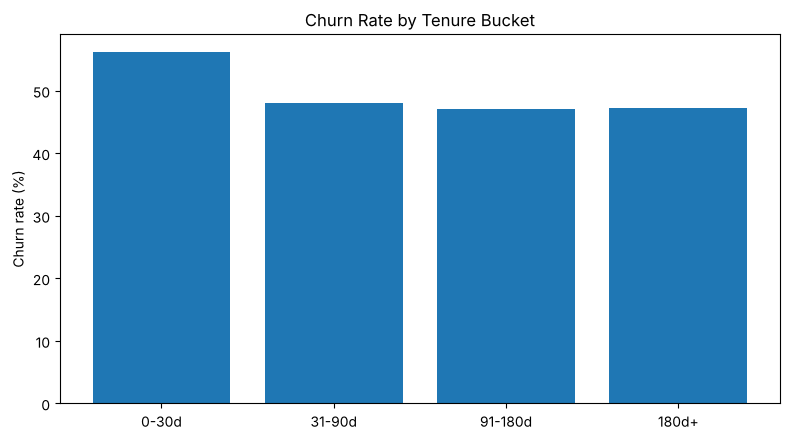

,signup_month,users,churn_rate,paid_conversion,avg_active_days,avg_listen_minutes,avg_content_actions
0,2025-01,1370,0.4708,0.1467,6.6562,39.2075,1.2686
1,2025-02,2098,0.4514,0.1497,6.6635,39.8868,1.1940
2,2025-03,2571,0.4535,0.1505,6.6138,39.3942,1.2349
3,2025-04,3027,0.4760,0.1629,6.4648,37.5763,1.1817
4,2025-05,3281,0.4788,0.1533,6.6327,39.5195,1.2079
5,2025-06,3439,0.4824,0.1547,6.5257,38.9806,1.1977
6,2025-07,3886,0.4681,0.1464,6.5878,40.0468,1.2257
7,2025-08,4000,0.4830,0.1578,6.4713,38.3062,1.1810
8,2025-09,3960,0.4689,0.1573,6.3861,38.7130,1.1364
9,2025-10,4236,0.4644,0.1624,6.5623,39.7044,1.2266


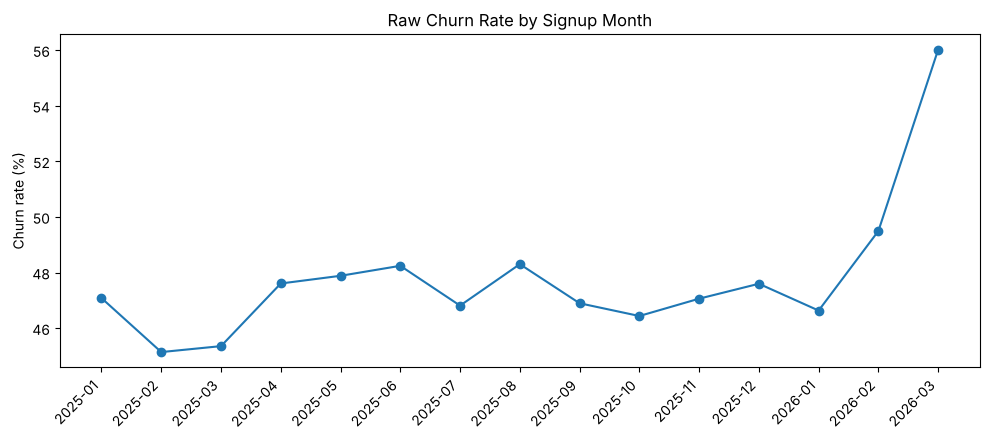

In [14]:
tenure = segment_summary(feature_table, 'tenure_bucket')
display(tenure)

ordered_labels = ['0-30d', '31-90d', '91-180d', '180d+']
tenure_plot = tenure.set_index('tenure_bucket').reindex(ordered_labels).reset_index()
plt.figure(figsize=(8, 4.5))
plt.bar(tenure_plot['tenure_bucket'].astype(str), tenure_plot['churn_rate'] * 100)
plt.title('Churn Rate by Tenure Bucket')
plt.ylabel('Churn rate (%)')
plt.tight_layout()
plt.show()

cohort = (
    feature_table.groupby('signup_month')
    .agg(
        users=('user_id', 'size'),
        churn_rate=('churn_label_14d', 'mean'),
        paid_conversion=('paid_conversion_30d', 'mean'),
        avg_active_days=('active_days_30d', 'mean'),
        avg_listen_minutes=('listen_minutes_30d', 'mean'),
        avg_content_actions=('content_actions_30d', 'mean'),
    )
    .reset_index()
    .sort_values('signup_month')
)
display(cohort)

plt.figure(figsize=(10, 4.5))
plt.plot(cohort['signup_month'], cohort['churn_rate'] * 100, marker='o')
plt.title('Raw Churn Rate by Signup Month')
plt.ylabel('Churn rate (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Facts

- Users with 0–30 days of tenure churn at about **56.19%**, with about 4.29 active days on average;
- Users with 31–90 days of tenure churn at about **48.05%**;
- Raw churn rises for recent signup months, while listening and content actions fall.

### Limitation

All users are observed at the same snapshot, so signup month is strongly tied to tenure. Recent cohorts have not yet formed mature behavior, so this does not support a causal claim that new-channel quality is deteriorating.

### Recommendation

Frame this as **early-activation risk**, not cohort deterioration. Production analysis should build snapshots across multiple months and compare signup cohorts at the same tenure day.

## 3.8 Trial Funnel: Conversion Efficiency by Channel

,acquisition_channel,users,trial_exposure_rate,start_rate_given_exposed,paid_conversion_given_started,paid_conversion_all,converted_users,churn_rate
0,app_store,12534,0.2616,0.4578,0.5606,0.1758,2203,0.4674
3,organic_search,11944,0.2582,0.4588,0.5396,0.1703,2034,0.4597
5,referral,6495,0.2762,0.4916,0.6849,0.2280,1481,0.3610
4,paid_social,8993,0.2321,0.4173,0.4749,0.1259,1132,0.6024
2,influencer,4036,0.2686,0.4769,0.5730,0.1863,752,0.4571
6,student_partner,3975,0.2636,0.4609,0.6082,0.1869,743,0.4714
1,email_campaign,2023,0.2506,0.4477,0.5768,0.1735,351,0.4686


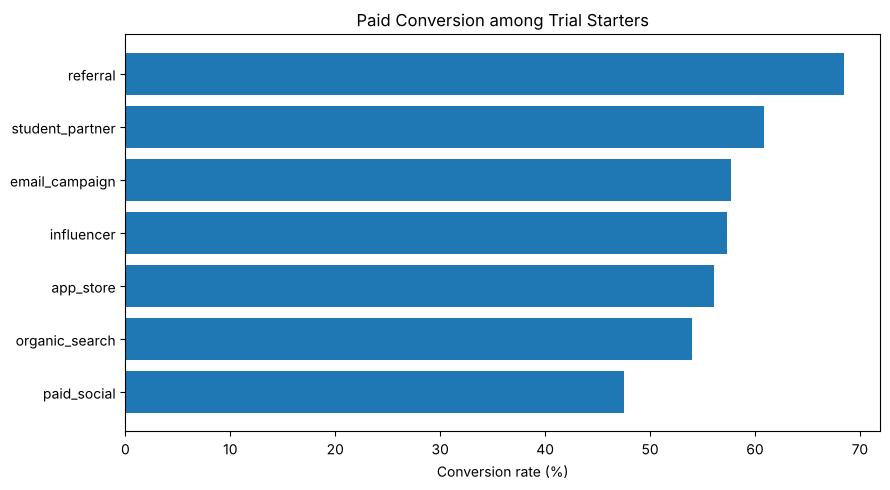

In [15]:
trial_rows = []
for channel_name, group in feature_table.groupby('acquisition_channel'):
    exposed = group[group['trial_exposed_30d'] == 1]
    started = group[group['trial_started_30d'] == 1]
    trial_rows.append({
        'acquisition_channel': channel_name,
        'users': len(group),
        'trial_exposure_rate': group['trial_exposed_30d'].mean(),
        'start_rate_given_exposed': exposed['trial_started_30d'].mean() if len(exposed) else np.nan,
        'paid_conversion_given_started': started['paid_conversion_30d'].mean() if len(started) else np.nan,
        'paid_conversion_all': group['paid_conversion_30d'].mean(),
        'converted_users': group['paid_conversion_30d'].sum(),
        'churn_rate': group['churn_label_14d'].mean(),
    })
trial_channel = pd.DataFrame(trial_rows).sort_values('converted_users', ascending=False)
display(trial_channel)

plot_data = trial_channel.sort_values('paid_conversion_given_started')
plt.figure(figsize=(9, 5))
plt.barh(plot_data['acquisition_channel'], plot_data['paid_conversion_given_started'] * 100)
plt.title('Paid Conversion among Trial Starters')
plt.xlabel('Conversion rate (%)')
plt.tight_layout()
plt.show()

### Facts

- `referral`: about **49.16%** of trial-exposed users start a trial, and about **68.49%** of trial starters convert to paid.
- `paid_social`: the same metrics are about **41.73%** and **47.49%**.

### Insight

Paid Social's problem does not end after acquisition; it persists through trial start and paid conversion. This looks more like a **mismatch between user intent and the ad's promise** than a payment-page problem.

### Recommendation

Build a dedicated funnel for Paid Social:

> Ad Promise → Landing → First Play → Content Save → Trial Start → Paid → D14 Retained

Decide whether to change the creative, onboarding, trial offer, or payment UX only after the specific drop-off point is confirmed.

# 4. Insight Synthesis: From Findings to Prioritized Opportunities

In [16]:
# Opportunity matrix across business dimensions. The dimensions overlap, so their figures cannot be added together.
opportunity_matrix = pd.DataFrame([
    {
        'opportunity': 'Casual-free activation',
        'evidence': '17,912 users; 64.93% churn; 48.91% of all churners',
        'business_value': 'High volume retention opportunity',
        'actionability': 'High: onboarding and content path',
        'validation': 'User-level A/B test on D14 retention',
    },
    {
        'opportunity': 'Premium revenue recovery',
        'evidence': '5,439 users; 57.51% churn; ~$10.17 avg 30d revenue',
        'business_value': 'High revenue protection',
        'actionability': 'High: payment retry and renewal intervention',
        'validation': 'Incremental recovered renewal revenue',
    },
    {
        'opportunity': 'Paid-social quality',
        'evidence': '60.24% churn; 12.59% paid conversion; 22.78% of churners',
        'business_value': 'Acquisition efficiency and LTV',
        'actionability': 'Medium: creative, landing, onboarding, bidding',
        'validation': 'Retained-paid conversion by campaign',
    },
    {
        'opportunity': 'Home recommendation efficiency',
        'evidence': '30.23% of listening events; 25.81% skip rate',
        'business_value': 'Large product surface',
        'actionability': 'Medium: cold-start and saveable content design',
        'validation': 'Retention + playlist add; skip-rate guardrail',
    },
    {
        'opportunity': 'Selective ad friction',
        'evidence': 'Ad-risk association is concentrated after activity stratification',
        'business_value': 'Retention without blanket revenue loss',
        'actionability': 'Medium: eligible-user frequency cap',
        'validation': 'Retention lift net of ad revenue loss',
    },
])
display(opportunity_matrix)

,opportunity,evidence,business_value,actionability,validation
0,Casual-free activation,"17,912 users; 64.93% churn; 48.91% of all chur...",High volume retention opportunity,High: onboarding and content path,User-level A/B test on D14 retention
1,Premium revenue recovery,"5,439 users; 57.51% churn; ~$10.17 avg 30d rev...",High revenue protection,High: payment retry and renewal intervention,Incremental recovered renewal revenue
2,Paid-social quality,60.24% churn; 12.59% paid conversion; 22.78% o...,Acquisition efficiency and LTV,"Medium: creative, landing, onboarding, bidding",Retained-paid conversion by campaign
3,Home recommendation efficiency,30.23% of listening events; 25.81% skip rate,Large product surface,Medium: cold-start and saveable content design,Retention + playlist add; skip-rate guardrail
4,Selective ad friction,Ad-risk association is concentrated after acti...,Retention without blanket revenue loss,Medium: eligible-user frequency cap,Retention lift net of ad revenue loss


### Guiding Principles

- **High rate, low volume**: may be a diagnostic issue, not necessarily a business priority;
- **High contribution**: has a scale impact on the overall metric;
- **High revenue at risk**: deserves a dedicated queue even if small;
- **Low actionability**: do not turn it straight into a strategy; keep investigating the mechanism;
- **Correlational analysis**: generates hypotheses;
- **A/B tests**: verify whether a strategy creates real incremental impact.

# 5. Churn Modeling: From Descriptive Analysis to Risk Ranking

## 5.1 Label, Feature Window, and Leakage Control

**Unit of modeling:** one row per user.

**Target:** `churn_label_14d`, whether the user churns in the 14 days after the snapshot.

**Features:** user profile, 7/30-day activity, listening, content actions, ads, and historical trial/payment signals, all from before the snapshot.

**Explicitly excluded:**

- `listen_events_14d`, `renewal_success_14d`: information from inside the prediction window;
- `churn_label_14d`, `retained_14d`: the target itself;
- `paid_conversion_30d`, `paid_started_30d`, `cancel_30d`: other outcome fields that may overlap the prediction window;
- Revenue outcomes: not used as model inputs, so current outcomes are not presented as behavioral drivers.

**Leakage audit:** rebuilding the features from raw events (`sql/01_user_metrics.sql`) showed that the provided `trial_used_before_snapshot` flag also counts 489 users whose first trial began after the snapshot. This notebook keeps the provided column; `src/churn_model.py` replaces it with the pre-snapshot-only version. Test ROC-AUC is 0.792 either way, so the leak does not affect the results here.

### Takeaway

> I defined a strict snapshot, observation window, and prediction window. I excluded any future-window or outcome-like fields to prevent leakage, even if they could improve offline accuracy.

In [17]:
target = 'churn_label_14d'

numeric_features = [
    'tenure_days',
    'active_days_7d',
    'listen_minutes_7d',
    'active_days_30d',
    'listen_minutes_30d',
    'sessions_30d',
    'avg_play_duration_sec_30d',
    'skip_rate_30d',
    'completion_rate_30d',
    'liked_songs_30d',
    'playlist_adds_30d',
    'search_events_30d',
    'ad_impressions_per_active_day',
    'ad_click_rate_30d',
    'ad_completion_rate_30d',
    'trial_used_before_snapshot',
    'payment_failed_30d',
]

categorical_features = [
    'country',
    'region_tier',
    'age_group',
    'primary_device',
    'acquisition_channel',
    'student_eligible',
    'marketing_opt_in',
    'music_persona',
    'subscription_type',
    'lifecycle_stage',
    'top_genre_30d',
]

model_features = numeric_features + categorical_features
X = feature_table[model_features].copy()
y = feature_table[target].copy()

print('Feature count:', len(model_features))
print('Positive rate:', f'{y.mean():.2%}')
print('The current target is not severely imbalanced; class weights will be treated as a sensitivity test.')

Feature count: 28
Positive rate: 47.56%
The current target is not severely imbalanced; class weights will be treated as a sensitivity test.


## 5.2 Train / Validation / Test Split

In [18]:
# 60% train / 20% validation / 20% untouched test.
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.25,
    stratify=y_train_full,
    random_state=RANDOM_STATE,
)

split_summary = pd.DataFrame({
    'split': ['train', 'validation', 'test'],
    'users': [len(X_train), len(X_val), len(X_test)],
    'churn_rate': [y_train.mean(), y_val.mean(), y_test.mean()],
})
display(split_summary)

,split,users,churn_rate
0,train,30000,0.4756
1,validation,10000,0.4756
2,test,10000,0.4756


## 5.3 Preprocessing Pipeline

In [19]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

# Logistic Regression uses drop='first' so each categorical coefficient has a reference group.
categorical_pipeline_lr = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='first')),
])

# Random Forest keeps all one-hot categories.
categorical_pipeline_rf = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])

preprocess_lr = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline_lr, categorical_features),
])

preprocess_rf = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline_rf, categorical_features),
])

## 5.4 Train Logistic Regression and Random Forest

In [20]:
models = {
    'Logistic Regression': Pipeline([
        ('preprocess', preprocess_lr),
        ('model', LogisticRegression(
            max_iter=2000,
            C=1.0,
            solver='liblinear',
            random_state=RANDOM_STATE,
        )),
    ]),
    'Random Forest': Pipeline([
        ('preprocess', preprocess_rf),
        ('model', RandomForestClassifier(
            n_estimators=120,
            max_depth=10,
            min_samples_leaf=20,
            max_features='sqrt',
            random_state=RANDOM_STATE,
            n_jobs=1,
        )),
    ]),
}

for name, model in models.items():
    print('Training:', name)
    model.fit(X_train, y_train)
    print('Trained:', name)

Training: Logistic Regression


Trained: Logistic Regression
Training: Random Forest


Trained: Random Forest


# 6. Model Validation: Beyond Accuracy

In [21]:
def evaluate_model(model, X_data, y_true, threshold=0.50):
    probability = model.predict_proba(X_data)[:, 1]
    prediction = (probability >= threshold).astype(int)
    return {
        'accuracy': accuracy_score(y_true, prediction),
        'precision': precision_score(y_true, prediction, zero_division=0),
        'recall': recall_score(y_true, prediction, zero_division=0),
        'f1': f1_score(y_true, prediction, zero_division=0),
        'roc_auc': roc_auc_score(y_true, probability),
        'pr_auc': average_precision_score(y_true, probability),
    }

metric_rows = []
for name, model in models.items():
    for split_name, X_data, y_data in [
        ('train', X_train, y_train),
        ('validation', X_val, y_val),
        ('test', X_test, y_test),
    ]:
        row = {'model': name, 'split': split_name}
        row.update(evaluate_model(model, X_data, y_data))
        metric_rows.append(row)

model_metrics = pd.DataFrame(metric_rows)
display(model_metrics)

,model,split,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression,train,0.7162,0.6840,0.7494,0.7152,0.7914,0.7440
1,Logistic Regression,validation,0.7123,0.6791,0.7489,0.7123,0.7871,0.7406
2,Logistic Regression,test,0.7183,0.6879,0.7464,0.7159,0.7921,0.7474
3,Random Forest,train,0.7270,0.6879,0.7797,0.7309,0.8094,0.7689
4,Random Forest,validation,0.7107,0.6713,0.7677,0.7162,0.7856,0.7350
5,Random Forest,test,0.7145,0.6780,0.7614,0.7172,0.7887,0.7425


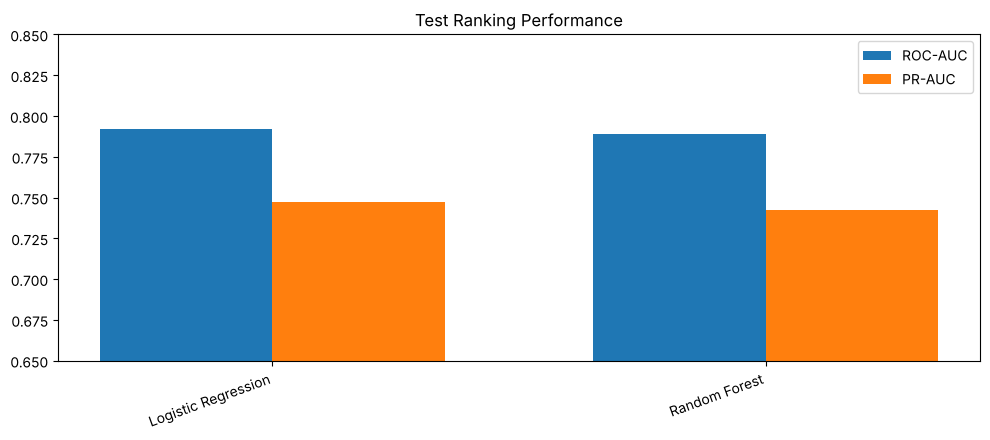

In [22]:
test_metrics = model_metrics[model_metrics['split'] == 'test'].copy()
plot_data = test_metrics.set_index('model')[['roc_auc', 'pr_auc']]

plt.figure(figsize=(10, 4.5))
x = np.arange(len(plot_data))
width = 0.35
plt.bar(x - width/2, plot_data['roc_auc'], width, label='ROC-AUC')
plt.bar(x + width/2, plot_data['pr_auc'], width, label='PR-AUC')
plt.xticks(x, plot_data.index, rotation=20, ha='right')
plt.ylim(0.65, 0.85)
plt.title('Test Ranking Performance')
plt.legend()
plt.tight_layout()
plt.show()

### Model Selection Insight

- Logistic Regression and Random Forest both reach about 0.79 test ROC-AUC, a negligible gap;
- Random Forest does not deliver a stable holdout improvement;
- Logistic Regression is easier to interpret, deploy, and monitor, so it is the better primary model for this version;
- The positive rate is 47.56%, not a severe class imbalance, so the primary model does not force class weights. If the production positive rate drops substantially, class weights can be added as a sensitivity test.

**Good model selection is not "the more complex model is better." It weighs:**

> Holdout performance + stability + interpretability + operational cost.

## 6.1 Confusion Matrix: Business Errors at the 0.5 Threshold

,Predicted Not Churn,Predicted Churn
Actual Not Churn,3633,1611
Actual Churn,1206,3550


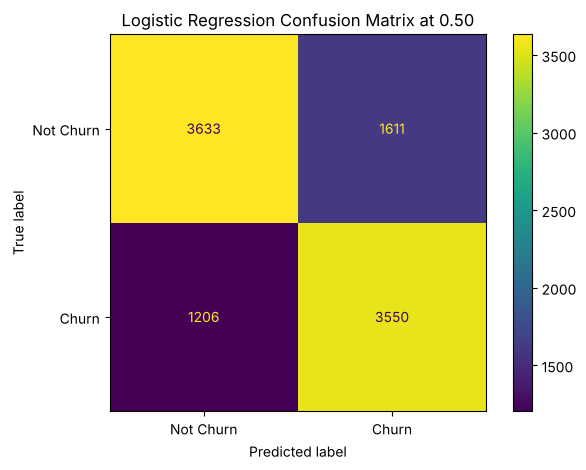

In [23]:
selected_model = models['Logistic Regression']
test_probability = selected_model.predict_proba(X_test)[:, 1]
test_prediction_05 = (test_probability >= 0.50).astype(int)

cm = confusion_matrix(y_test, test_prediction_05)
display(pd.DataFrame(
    cm,
    index=['Actual Not Churn', 'Actual Churn'],
    columns=['Predicted Not Churn', 'Predicted Churn'],
))

ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Not Churn', 'Churn']).plot()
plt.title('Logistic Regression Confusion Matrix at 0.50')
plt.tight_layout()
plt.show()

### Business Interpretation

- False positive: a user who would not churn receives an intervention, costing budget and creating user friction;
- False negative: a user who churns is not identified, losing the user and their revenue;
- The 0.5 threshold is a technical default, not the business optimum.

## 6.2 Threshold Tuning: Choose the Threshold on Validation Data

,threshold,predicted_positive_rate,precision,recall,f1
0,0.2000,0.8099,0.5686,0.9683,0.7165
1,0.2500,0.7666,0.5849,0.9428,0.7219
2,0.3000,0.7229,0.6045,0.9188,0.7292
3,0.3500,0.6766,0.6242,0.8879,0.7330
4,0.4000,0.6290,0.6418,0.8488,0.7309
5,0.4500,0.5804,0.6608,0.8063,0.7263
6,0.5000,0.5245,0.6791,0.7489,0.7123
7,0.5500,0.4617,0.7002,0.6798,0.6899
8,0.6000,0.3873,0.7201,0.5864,0.6464
9,0.6500,0.3059,0.7525,0.4840,0.5891


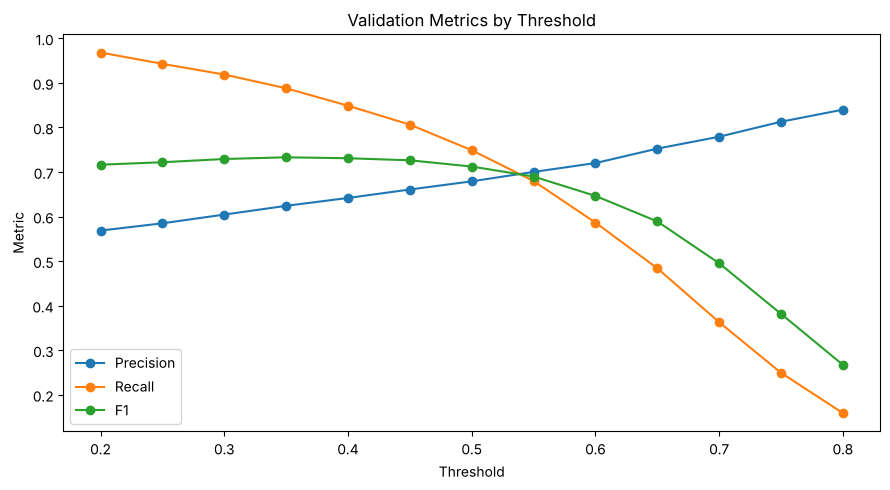

In [24]:
def build_threshold_table(model, X_data, y_true, thresholds):
    probability = model.predict_proba(X_data)[:, 1]
    rows = []
    for threshold in thresholds:
        prediction = (probability >= threshold).astype(int)
        rows.append({
            'threshold': threshold,
            'predicted_positive_rate': prediction.mean(),
            'precision': precision_score(y_true, prediction, zero_division=0),
            'recall': recall_score(y_true, prediction, zero_division=0),
            'f1': f1_score(y_true, prediction, zero_division=0),
        })
    return pd.DataFrame(rows)

thresholds = np.arange(0.20, 0.81, 0.05)
threshold_table = build_threshold_table(selected_model, X_val, y_val, thresholds)
display(threshold_table)

plt.figure(figsize=(9, 5))
plt.plot(threshold_table['threshold'], threshold_table['precision'], marker='o', label='Precision')
plt.plot(threshold_table['threshold'], threshold_table['recall'], marker='o', label='Recall')
plt.plot(threshold_table['threshold'], threshold_table['f1'], marker='o', label='F1')
plt.title('Validation Metrics by Threshold')
plt.xlabel('Threshold')
plt.ylabel('Metric')
plt.legend()
plt.tight_layout()
plt.show()

### Key Judgment

On the validation set, a threshold of about 0.35 gives the highest F1, but it would flag about two-thirds of users as high risk, more than an operations team can usually handle.

The more common decision in practice:

> First set the Top-K that the budget can reach, then evaluate Precision@K, recall capture, and lift.

This fits real operating constraints better than mechanically picking the threshold with the highest F1.

## 6.3 Top-K Lift: Evaluating the Model When Outreach Capacity Is Limited

,top_fraction,users_targeted,precision_at_k,recall_capture,lift_vs_baseline
0,0.0500,500,0.8680,0.0913,1.8251
1,0.1000,1000,0.8470,0.1781,1.7809
2,0.1500,1500,0.8213,0.2590,1.7269
3,0.2000,2000,0.7965,0.3349,1.6747
4,0.3000,3000,0.7643,0.4821,1.6071


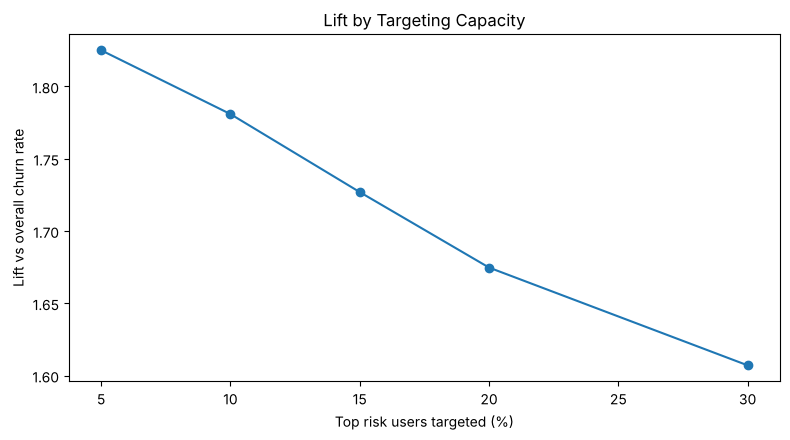

In [25]:
def top_k_metrics(probability, y_true, fractions):
    ranked = pd.DataFrame({
        'probability': np.asarray(probability),
        'actual': np.asarray(y_true),
    }).sort_values('probability', ascending=False).reset_index(drop=True)
    baseline = ranked['actual'].mean()
    total_positive = ranked['actual'].sum()
    rows = []
    for fraction in fractions:
        n = int(np.ceil(len(ranked) * fraction))
        top = ranked.head(n)
        rows.append({
            'top_fraction': fraction,
            'users_targeted': n,
            'precision_at_k': top['actual'].mean(),
            'recall_capture': top['actual'].sum() / total_positive,
            'lift_vs_baseline': top['actual'].mean() / baseline,
        })
    return pd.DataFrame(rows)

topk = top_k_metrics(test_probability, y_test, [0.05, 0.10, 0.15, 0.20, 0.30])
display(topk)

plt.figure(figsize=(8, 4.5))
plt.plot(topk['top_fraction'] * 100, topk['lift_vs_baseline'], marker='o')
plt.title('Lift by Targeting Capacity')
plt.xlabel('Top risk users targeted (%)')
plt.ylabel('Lift vs overall churn rate')
plt.tight_layout()
plt.show()

### Test-Set Result

- The top 10% of risk users have an actual churn rate of about **84.7%**, a lift of about **1.78x**;
- The top 20% of risk users have an actual churn rate of about **79.7%**, capture about **33.5%** of all churners, and show a lift of about **1.67x**;
- The model is best used for **risk ranking and capacity allocation**, not just to output a 0/1 label.

## 6.4 Risk Deciles: Are Ranking and Calibration Reasonable?

,risk_decile,users,avg_predicted_risk,actual_churn_rate,churners,capture_share
0,D1,1000,0.0379,0.0320,32,0.0067
1,D2,1000,0.1500,0.1490,149,0.0313
2,D3,1000,0.2670,0.2600,260,0.0547
3,D4,1000,0.3746,0.3900,390,0.0820
4,D5,1000,0.4708,0.4580,458,0.0963
5,D6,1000,0.5504,0.5750,575,0.1209
6,D7,1000,0.6163,0.5990,599,0.1259
7,D8,1000,0.6824,0.7000,700,0.1472
8,D9,1000,0.7498,0.7460,746,0.1569
9,D10,1000,0.8420,0.8470,847,0.1781


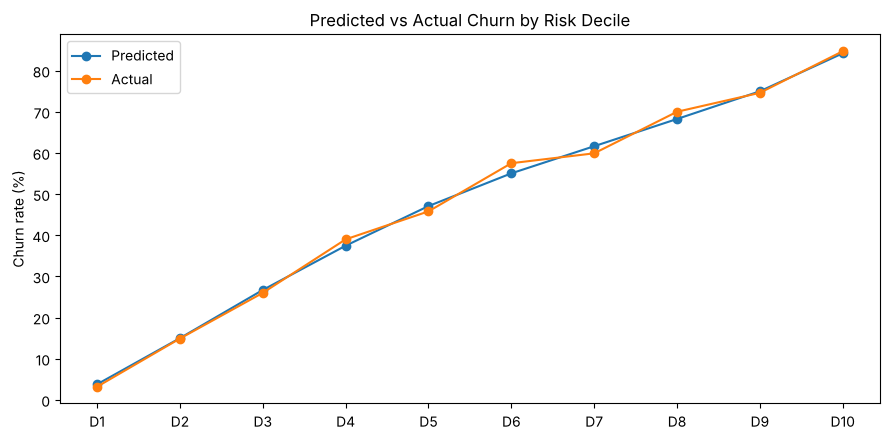

In [26]:
risk_decile = pd.DataFrame({
    'actual_churn': np.asarray(y_test),
    'predicted_churn': test_probability,
})
risk_decile['risk_decile'] = pd.qcut(
    risk_decile['predicted_churn'],
    q=10,
    labels=[f'D{i}' for i in range(1, 11)],
)

decile_summary = (
    risk_decile.groupby('risk_decile', observed=True)
    .agg(
        users=('actual_churn', 'size'),
        avg_predicted_risk=('predicted_churn', 'mean'),
        actual_churn_rate=('actual_churn', 'mean'),
        churners=('actual_churn', 'sum'),
    )
    .reset_index()
)
decile_summary['capture_share'] = decile_summary['churners'] / decile_summary['churners'].sum()
display(decile_summary)

plt.figure(figsize=(9, 4.5))
plt.plot(decile_summary['risk_decile'].astype(str), decile_summary['avg_predicted_risk'] * 100, marker='o', label='Predicted')
plt.plot(decile_summary['risk_decile'].astype(str), decile_summary['actual_churn_rate'] * 100, marker='o', label='Actual')
plt.title('Predicted vs Actual Churn by Risk Decile')
plt.ylabel('Churn rate (%)')
plt.legend()
plt.tight_layout()
plt.show()

### Validation Insight

The highest-risk decile has an actual churn rate of about 85%, and the lowest about 3.2%, showing clear ranking ability.

Predicted and actual rates are close overall, but before going to production you should still:

- Run out-of-time validation across multiple snapshots;
- Monitor calibration drift;
- Calibrate the probabilities if they feed directly into economic value calculations, instead of relying on raw `predict_proba`.

# 7. Model Interpretation: Which Signals Drive Risk

## 7.1 Logistic Regression Coefficients

,feature,coefficient,odds_ratio,abs_coefficient
48,cat__music_persona_low_intent_new,0.6514,1.9182,0.6514
41,cat__acquisition_channel_paid_social,0.4183,1.5194,0.4183
52,cat__subscription_type_free,0.3613,1.4353,0.3613
54,cat__subscription_type_student_premium,0.1980,1.2190,0.1980
57,cat__lifecycle_stage_inactive,0.1384,1.1485,0.1384
29,cat__age_group_18-24,0.0930,1.0974,0.0930
33,cat__age_group_55+,0.0738,1.0766,0.0738
53,cat__subscription_type_individual_premium,0.0525,1.0539,0.0525
23,cat__country_JP,0.0493,1.0505,0.0493
62,cat__top_genre_30d_edm,0.0470,1.0481,0.0470


,feature,coefficient,odds_ratio,abs_coefficient
5,num__sessions_30d,-0.9144,0.4008,0.9144
49,cat__music_persona_playlist_builder,-0.6352,0.5298,0.6352
42,cat__acquisition_channel_referral,-0.3969,0.6724,0.3969
59,cat__lifecycle_stage_premium_engaged,-0.3352,0.7152,0.3352
58,cat__lifecycle_stage_premium_at_risk,-0.2303,0.7943,0.2303
47,cat__music_persona_discovery_seeker,-0.2224,0.8006,0.2224
51,cat__music_persona_social_listener,-0.1911,0.8260,0.1911
65,cat__top_genre_30d_jazz,-0.1816,0.8340,0.1816
46,cat__music_persona_commute_listener,-0.1748,0.8396,0.1748
69,cat__top_genre_30d_no_listening,-0.1717,0.8423,0.1717


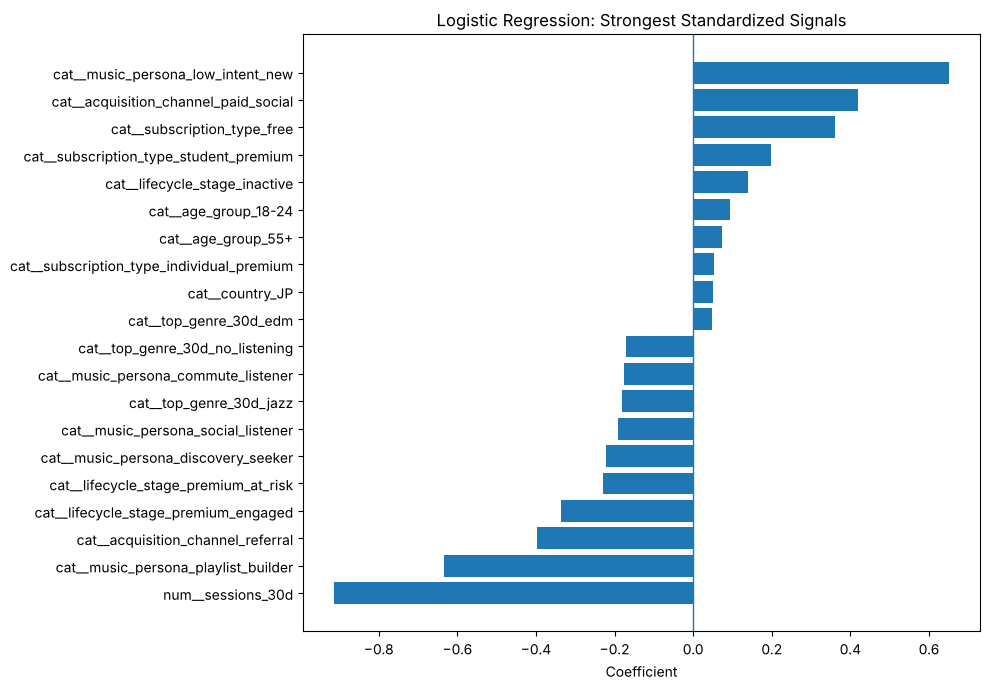

In [27]:
lr_feature_names = selected_model.named_steps['preprocess'].get_feature_names_out()
lr_coefficients = selected_model.named_steps['model'].coef_[0]

coefficient_table = pd.DataFrame({
    'feature': lr_feature_names,
    'coefficient': lr_coefficients,
    'odds_ratio': np.exp(lr_coefficients),
})
coefficient_table['abs_coefficient'] = coefficient_table['coefficient'].abs()

display(coefficient_table.sort_values('coefficient', ascending=False).head(15))
display(coefficient_table.sort_values('coefficient').head(15))

top_coef = pd.concat([
    coefficient_table.nsmallest(10, 'coefficient'),
    coefficient_table.nlargest(10, 'coefficient'),
]).sort_values('coefficient')

plt.figure(figsize=(10, 7))
plt.barh(top_coef['feature'], top_coef['coefficient'])
plt.axvline(0, linewidth=1)
plt.title('Logistic Regression: Strongest Standardized Signals')
plt.xlabel('Coefficient')
plt.tight_layout()
plt.show()

### Interpretation

- Categories such as `low_intent_new`, `paid_social`, and `free` are associated with higher predicted risk;
- `sessions_30d`, `active_days_30d`, `playlist_builder`, and `referral` are associated with lower risk;
- Numeric features are standardized, so each coefficient is the change in log-odds per one-standard-deviation increase;
- Categorical coefficients are relative to the one-hot reference category;
- These are **predictive associations, not causal effects**.

### Takeaway

The right reading is not that one more session reduces churn. More precisely:

> Session frequency is a strong early signal of habit formation. I would use it for risk identification, but validate any intervention intended to increase sessions through an experiment.

## 7.2 Random Forest Feature Importance

,feature,importance
3,num__active_days_30d,0.1441
5,num__sessions_30d,0.1332
4,num__listen_minutes_30d,0.0992
11,num__search_events_30d,0.0837
1,num__active_days_7d,0.0605
2,num__listen_minutes_7d,0.0560
65,cat__lifecycle_stage_casual_free,0.0379
69,cat__lifecycle_stage_premium_engaged,0.0372
7,num__skip_rate_30d,0.0335
61,cat__subscription_type_free,0.0324


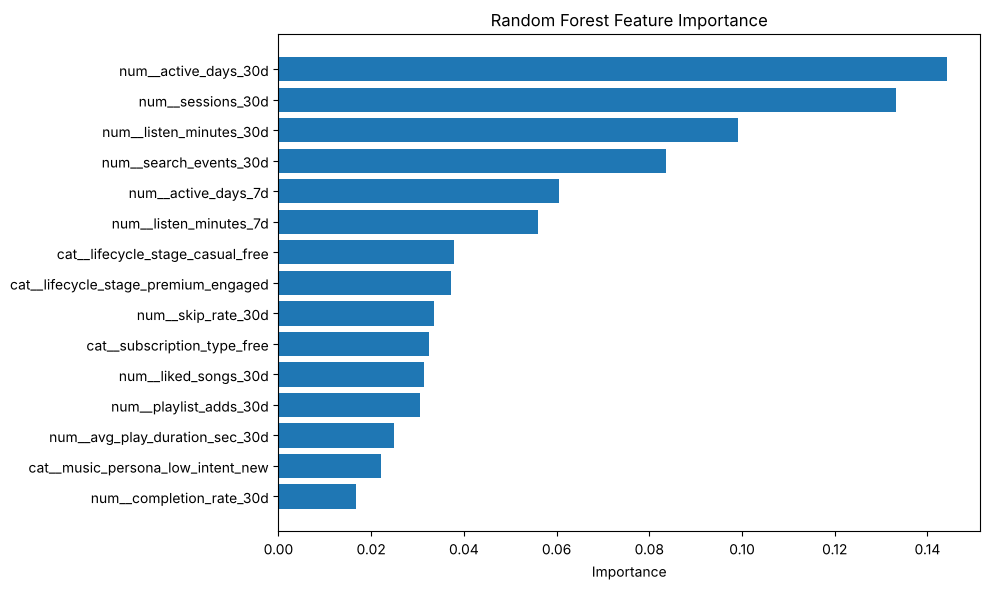

In [28]:
rf_model = models['Random Forest']
rf_feature_names = rf_model.named_steps['preprocess'].get_feature_names_out()
rf_importance = pd.DataFrame({
    'feature': rf_feature_names,
    'importance': rf_model.named_steps['model'].feature_importances_,
}).sort_values('importance', ascending=False)

display(rf_importance.head(20))

plot_data = rf_importance.head(15).sort_values('importance')
plt.figure(figsize=(10, 6))
plt.barh(plot_data['feature'], plot_data['importance'])
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

### Interpretation Limitation

Random Forest importance shows which variables often help the trees split, but it:

- Does not show direction;
- Can be biased toward continuous or high-cardinality variables;
- Splits importance across correlated features;
- Cannot serve as causal evidence.

Here it mainly serves as a robustness check on the Logistic Regression results, not as the sole basis for business strategy.

# 8. Operational Risk Scoring: From Model to User Queues

In [29]:
# Model selection is already finished on the independent test set.
# For deployment, retrain on train + validation; test metrics stay as reported and are not used for tuning.
X_train_deploy = pd.concat([X_train, X_val], axis=0)
y_train_deploy = pd.concat([y_train, y_val], axis=0)

deployment_model = Pipeline([
    ('preprocess', preprocess_lr),
    ('model', LogisticRegression(max_iter=2000, C=1.0, solver='liblinear', random_state=RANDOM_STATE)),
])
deployment_model.fit(X_train_deploy, y_train_deploy)

scored_users = feature_table.copy()
scored_users['churn_score'] = deployment_model.predict_proba(scored_users[model_features])[:, 1]
scored_users['risk_percentile'] = scored_users['churn_score'].rank(pct=True)
scored_users['top20_risk'] = scored_users['risk_percentile'] >= 0.80

risk_queue = scored_users[scored_users['top20_risk']]
print('Top 20% score cutoff:', f"{risk_queue['churn_score'].min():.4f}")
print('Users in queue:', len(risk_queue))
print('Observed churn rate in queue:', f"{risk_queue['churn_label_14d'].mean():.2%}")

display(
    risk_queue.groupby('lifecycle_stage')
    .agg(
        users=('user_id', 'size'),
        avg_score=('churn_score', 'mean'),
        observed_churn=('churn_label_14d', 'mean'),
        avg_revenue=('total_revenue_30d', 'mean'),
    )
    .sort_values('users', ascending=False)
)

Top 20% score cutoff: 0.7140
Users in queue: 10001
Observed churn rate in queue: 79.59%


,users,avg_score,observed_churn,avg_revenue
lifecycle_stage,,,,
casual_free,5157,0.7802,0.7818,0.0339
inactive,4162,0.8172,0.8162,0.0276
premium_at_risk,556,0.7542,0.7770,10.1465
trial_user,126,0.7685,0.7857,0.0113


### Risk Queue Insight

The top-20% risk queue is made up mostly of `casual_free` and `inactive` users, but also includes a small group of `premium_at_risk` users:

- Free risk users are numerous, suited to low-cost, product-led interventions;
- Premium risk users are few but high-revenue, and should go to a separate manual or payment-recovery queue.

**Do not send the same intervention down the list from highest to lowest risk.** Risk, value, the actionable reason, and outreach cost must jointly decide the strategy.

## 8.1 Queue Assignment: Mutually Exclusive Strategies and Priority

,strategy_queue,users,avg_churn_score,observed_churn_rate,avg_active_days,avg_total_revenue
0,01_premium_recovery,1119,0.7173,0.7274,0.8695,10.1592
1,02_activation_rescue,9445,0.7963,0.7970,0.9314,0.0308
2,03_paid_social_remediation,813,0.6846,0.6974,3.9865,0.0755
3,04_selective_ad_test,1060,0.6643,0.6396,2.0802,0.0723
4,05_search_to_playlist,1108,0.5821,0.5948,4.8646,0.0792
5,06_monitor_only,36455,0.3712,0.3712,8.2603,5.0096


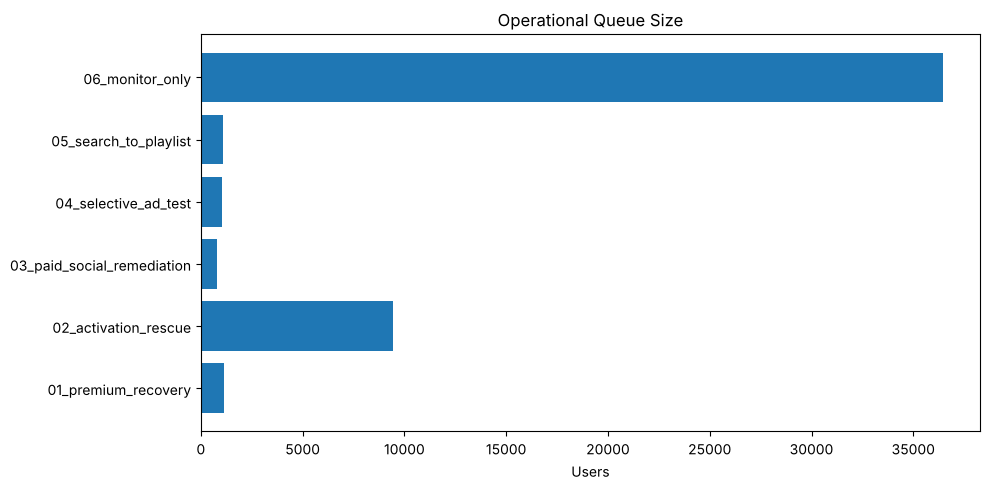

In [30]:
# Queues must be mutually exclusive so no user receives more than one treatment.
# Priority: Revenue protection > New-user activation > Channel remediation > Ad test > Search-to-playlist.

conditions = [
    (
        scored_users['lifecycle_stage'].eq('premium_at_risk') &
        (scored_users['churn_score'] >= 0.65)
    ),
    (
        scored_users['lifecycle_stage'].isin(['casual_free', 'inactive', 'trial_user']) &
        scored_users['top20_risk']
    ),
    (
        scored_users['acquisition_channel'].eq('paid_social') &
        (scored_users['churn_score'] >= 0.65)
    ),
    (
        scored_users['subscription_type'].eq('free') &
        scored_users['active_level_30d'].isin(['low', 'medium']) &
        scored_users['ad_load_bucket'].isin(['medium', 'high']) &
        (scored_users['churn_score'] >= 0.60)
    ),
    (
        scored_users['subscription_type'].isin(['free', 'trial']) &
        (scored_users['search_events_30d'] >= 2) &
        (scored_users['content_actions_30d'] == 0) &
        (scored_users['churn_score'] >= 0.50)
    ),
]

choices = [
    '01_premium_recovery',
    '02_activation_rescue',
    '03_paid_social_remediation',
    '04_selective_ad_test',
    '05_search_to_playlist',
]

scored_users['strategy_queue'] = np.select(conditions, choices, default='06_monitor_only')

queue_summary = (
    scored_users.groupby('strategy_queue')
    .agg(
        users=('user_id', 'size'),
        avg_churn_score=('churn_score', 'mean'),
        observed_churn_rate=('churn_label_14d', 'mean'),
        avg_active_days=('active_days_30d', 'mean'),
        avg_total_revenue=('total_revenue_30d', 'mean'),
    )
    .reset_index()
    .sort_values('strategy_queue')
)
display(queue_summary)

plt.figure(figsize=(10, 5))
plt.barh(queue_summary['strategy_queue'], queue_summary['users'])
plt.title('Operational Queue Size')
plt.xlabel('Users')
plt.tight_layout()
plt.show()

# 9. Strategy: Specific, Segmented, Actionable, and Testable

## Strategy 1: Premium Revenue Recovery

**Target rule**

- `premium_at_risk`;
- churn score ≥ 0.65;
- Prioritize users with `payment_failed_30d = 1`, declining recent activity, or an upcoming renewal.

**Why this segment**

- Average 30-day revenue of about $10.17;
- 57.51% churn rate;
- The goal of this queue is not to maximize reach but to protect recurring revenue.

**Action sequence**

1. Payment failed: payment retry, payment-method update, and a grace period first;
2. Payment fine but activity declining: show unfinished playlists, recent likes, and personalized return content;
3. Weak awareness of benefits: show the value the user actually gets before renewal, instead of discounting.

**Primary KPI**

- Incremental renewal success;
- Recovered subscription revenue per eligible user.

**Guardrails**

- Refund rate;
- Support contact rate;
- Discount cost.

## Strategy 2: Activation Rescue for Casual-Free / Inactive

**Target rule**

- `casual_free`, `inactive`, or `trial_user`;
- Top 20% model risk;
- Active days, sessions, and content actions determine the specific content path.

**Why this is not a generic push campaign**

The model and behavioral analysis both show that the biggest problem is users not forming a repeatable content asset. The intervention should follow the user's known signals:

- Searches but no likes: Search-to-Playlist;
- Plays but a high skip rate: reduce exploration noise with situational playlists;
- No activity at all: test a lightweight onboarding first, without discounts.

**Primary KPI**

- D14 retention among eligible users.

**Secondary KPIs**

- Active days;
- Playlist add rate;
- Sessions per user.

**Guardrail**

- Skip rate;
- Notification opt-out.

## Strategy 3: Paid Social Remediation

**Target diagnosis**

Paid Social shows high churn, low trial-to-paid conversion, and low average revenue at once, so the problem runs through the entire user journey.

**Action**

- Track retained-paid conversion by campaign / creative / device;
- Check that ad promises are consistent with the first onboarding screen;
- Separately check Android permissions, login, payment, and page-load issues;
- Shift budget optimization from CPA to expected retained LTV.

**Why not just cut the budget**

Cutting Paid Social directly also cuts new-user volume. The right approach is to first find whether the quality gap comes from creative, audience, landing page, or product experience, then run budget experiments.

## Strategy 4: Selective Ad-Friction Test

**Target rule**

- Free users;
- low / medium activity;
- medium / high ad load;
- churn score ≥ 0.60.

**Treatment**

- Delay the first ad;
- Reduce ad frequency in the first 3 sessions;
- Restore the standard ad policy after the user saves a playlist.

**Why selective**

The stratified analysis shows the raw link between ads and churn is confounded by activity. Reducing ads site-wide would hurt revenue without necessarily fixing the main churn problem.

**Decision metric**

> Incremental retained users × expected future value − lost ad revenue.

This is closer to a real business decision than looking at retention lift alone.

## Strategy 5: Search-to-Playlist Product Loop

**Target rule**

- Free or Trial users;
- At least 2 searches in 30 days;
- No likes or playlist adds;
- Medium-to-high churn risk.

**Product hypothesis**

Searching users have expressed clear intent but have not turned it into content they can return to. Turning search results directly into a saveable playlist may work better than adding more home recommendations.

**Treatment examples**

- "Save this search as a playlist";
- Generate a temporary mix from consecutive searches;
- Restore that search path the next time the user opens the app.

**Primary metric**

- D14 retention.

**Mechanism metrics**

- Playlist add rate;
- Repeat session rate;
- Search-to-play conversion.

**Guardrail**

- Skip rate and hide-recommendation rate.

# 10. A/B Test Design: Validate the Strategy, Not the Model

## Example Experiment: High-Risk New User Playlist Activation

| Element | Design |
|---|---|
| Business goal | Lift D14 retention for high-risk new users |
| Eligible population | Tenure ≤ 30 days, free/trial, top risk, no saved content yet |
| Randomization unit | user_id |
| Control | Current home experience |
| Treatment | Saveable situational playlists + search-to-playlist entry point |
| Primary metric | D14 retention |
| Secondary metrics | Active days, playlist adds, repeat sessions |
| Guardrails | Skip rate, notification opt-out, page latency |
| Quality checks | SRM, exposure logging, eligibility consistency |
| Decision rule | Statistically significant + meets MDE + acceptable guardrails |

A second experiment, on paywall messaging, is sized in `src/ab_test_design.py` and described in the repository README.

### Methodology Note

The risk model answers: **who is most likely to churn?**

The A/B test answers: **does this intervention make these users churn less?**

High risk does not mean high recoverability. Once enough experiment data accumulates, an uplift / treatment-effect model can identify the users whose behavior an intervention can actually change.

# 11. Production Monitoring: Running the System After Launch

## Daily / Weekly Operating System

### 1. Feature Pipeline

- Generate each user's 7/30-day behavioral features daily;
- Check data latency, nulls, duplicate users, and abnormal distributions;
- Keep feature and model versions traceable.

### 2. Scoring

- Score in daily or weekly batches;
- Set Top-K from the budget rather than a fixed global threshold;
- Maintain a suppression list so the same user is not in multiple experiments or campaigns at once.

### 3. Model Monitoring

- Score distribution;
- Feature drift / PSI;
- Missing rate;
- Top 10% / 20% actual churn rate;
- ROC-AUC, PR-AUC, and calibration, backfilled once labels mature.

### 4. Strategy Monitoring

- Eligible users;
- Exposed users;
- Treatment take-up;
- Incremental retention;
- Revenue saved / incentive cost;
- Guardrail deterioration.

### 5. Retraining Trigger

Do not retrain on a fixed weekly schedule. Retrain when:

- Key features drift beyond a threshold;
- Top-K precision declines for consecutive periods;
- The product or ad mechanics change structurally;
- Enough new mature labels accumulate.

# 12. Project Summary

> I built an end-to-end retention and churn-risk analysis for Spiffy, a music-streaming platform. I started by validating a user-level feature table built from listening, subscription, and ad events. The overall 14-day churn rate was 47.6%, but the key finding was that churn was highly concentrated: casual-free users contributed almost half of all churners, while premium-at-risk users represented a smaller but high-revenue recovery opportunity.
>
> I then segmented users by lifecycle, acquisition channel, content behavior, recommendation source, ad load, and trial funnel. Paid Social had a 60.2% churn rate and only 12.6% paid conversion, while Referral had much stronger retention and conversion. At the product level, home recommendations generated the most listening events but also had a 25.8% skip rate, compared with only 8.3% for user playlists. This suggested that early content ownership and repeatable listening paths were stronger intervention opportunities than simply adding more recommendations.
>
> For prediction, I compared Logistic Regression and Random Forest using a strict feature window and excluded future outcomes to prevent leakage. Logistic Regression achieved about 0.79 ROC-AUC on the untouched test set and produced strong ranking lift: the top 20% risk users had an observed churn rate of about 79.7%, or 1.67 times the baseline. Because the complex model did not materially improve holdout performance, I selected Logistic Regression for interpretability and operational stability.
>
> Finally, I converted risk scores into separate operational queues: activation rescue for casual-free users, revenue recovery for premium users, Paid Social remediation, selective ad-frequency experiments, and a Search-to-Playlist product loop. I would validate each treatment with user-level A/B tests and monitor both incremental retention and revenue guardrails. The key distinction is that the churn model prioritizes risk, while experiments prove whether an intervention creates causal lift.

# 13. Design Decisions (Q&A)

1. **Why did you use a user-level table instead of raw events?**  
   Churn is a user-level outcome; modeling on the event table would duplicate users and overweight heavy users.

2. **How did you prevent data leakage?**  
   By defining a snapshot, an observation window, and a prediction window, and excluding behavior from the next 14 days and outcome-type fields. Rebuilding the features from raw events also caught a trial flag that counted post-snapshot trials.

3. **Why not choose Random Forest?**  
   RF did not deliver a stable improvement on the independent holdout; LR is more interpretable, stable, and easier to deploy.

4. **Why is Accuracy insufficient?**  
   Classification errors carry different costs; precision, recall, PR-AUC, and Top-K lift are needed as well.

5. **Why use Top-K instead of a threshold?**  
   The operations budget is a capacity constraint. Top-K maps directly to how many users can be reached and the value per unit of budget.

6. **Does feature importance prove causality?**  
   No. The model is for prediction; strategy effects are validated with randomized experiments.

7. **What is the biggest limitation?**  
   There is only one snapshot, so there is no out-of-time validation; production would need multiple snapshots and drift monitoring.

8. **How would you improve the project next?**  
   Add multiple snapshots, campaign-level acquisition cost, long-term user value, and experiment treatment labels, then build uplift models once experiment data accumulates.

# 14. Final Takeaways

- **Largest-scale problem:** Casual-free users have not formed a stable content habit;
- **Largest channel problem:** Paid Social's quality loss runs through onboarding, trial, and paid conversion;
- **Largest product opportunity:** Turn high-intent searches into saveable, repeatable content paths;
- **Ads:** Ad load is not a single root cause; run selective frequency-cap experiments rather than reducing ads site-wide;
- **Model:** Logistic Regression already provides stable risk ranking; the more complex model adds no clear gain;
- **Operating principle:** Risk, value, cause, capacity, and testability jointly determine user strategy;
- **Methodological boundary:** Analysis and models generate hypotheses; A/B tests validate incremental impact.